#Business Analytics

**Tema:** Analítica Predictiva sobre los registros de Violencia Intrafamiliar en Colombia (2015-2024).

**Nivel:** 9.º Semestre - Ingeniería de Sistemas.

**Dataset:** Violencia intrafamiliar. Colombia, años 2015 a 2024.

**Integrantes:**
- Martin Daniel Montaño B
- Johan Sneider Cortes Bernal

## Objetivos de la Sesión

1. **Analítica Predictiva:** desarrollar modelos de Machine Learning para estimar el escenario del hecho registrado.
2. **Preprocesamiento:** preparar variables categóricas y numéricas para su utilización en los algoritmos.
3. **Entrenamiento:** implementar y comparar diferentes modelos de clasificación.
4. **Evaluación:** analizar el rendimiento mediante métricas de clasificación.
5. **Interpretabilidad:** identificar las características que más contribuyen a las predicciones del modelo.

## Metodología

- Carga y preparación del dataset.
- Selección de la variable objetivo y características predictoras.
- Ingeniería y transformación de variables.
- División de datos en entrenamiento y prueba.
- Entrenamiento de modelos de clasificación.
- Evaluación y comparación de resultados.
- Análisis de importancia de características.

In [1]:
# ==========================================
# 0. CONFIGURACIÓN DEL ENTORNO Y CARGA DE DATOS
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

# Configuración visual
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

pd.set_option("display.max_columns", None)

# Carga del dataset desde Datos Abiertos Colombia
url_api = (
    "https://www.datos.gov.co/resource/ers2-kerr.csv"
    "?$limit=500000"
)

df_original = pd.read_csv(url_api)

# Crear copia de trabajo
df_clean = df_original.copy()

# Limpieza básica de texto
columnas_texto = df_clean.select_dtypes(
    include=["object", "string"]
).columns

for columna in columnas_texto:
    df_clean[columna] = (
        df_clean[columna]
        .astype("string")
        .str.strip()
    )

# Normalización temporal
for columna in ["mes_del_hecho", "dia_del_hecho"]:
    df_clean[columna] = (
        df_clean[columna]
        .str.lower()
        .str.capitalize()
    )

df_clean["a_o_del_hecho"] = pd.to_numeric(
    df_clean["a_o_del_hecho"],
    errors="coerce"
)

print("Dataset preparado correctamente.")
print("Dimensiones:", df_clean.shape)

display(df_clean.head())

Dataset preparado correctamente.
Dimensiones: (236840, 36)


,id,a_o_del_hecho,sexo_de_la_victima,grupo_de_edad_quinquenal,grupo_mayor_menor_de_edad,grupo_de_edad_judicial,ciclo_vital,pais_de_nacimiento,escolaridad,estado_civil,tipo_de_discapacidad,pertenencia_etnica,orientacion_sexual,identidad_de_genero,transgenero,pertenencia_grupal,mes_del_hecho,dia_del_hecho,rango_de_hora_del_hecho_x_3_horas,codigo_dane_municipio,municipio_del_hecho_dane,departamento_del_hecho_dane,codigo_dane_departamento,localidad_del_hecho,zona_del_hecho,escenario_del_hecho,actividad_durante_el_hecho,circunstancia_del_hecho_detallada,contexto_del_hecho,mecanismo_causal_de_la_lesion_no_fatal,diagnostico_topografico_de_la_lesion_no_fatal,sexo_del_agresor,presunto_agresor_detallado,factor_desencadenante_de_la_agresion,dias_de_incapacidad_medicolegal,pueblo_indigena
0,1,2015,Hombre,(10 a 14),a) Menor de Edad (<18 Años),(10 a 13),(12 a 17) Adolescencia,Colombia,Básica primaria,Soltero (a),Ninguna,Sin información,No Sabe / No Informa,No Sabe / No Informa,No Sabe / No Informa,Sin información,Diciembre,Martes,(18:00 a 20:59),11001,"Bogotá, D.C.","Bogotá, D.C.",11,Rafael Uribe Uribe,Cabecera municipal,"Calle (Autopista,Avenida,Dentro de La Ciudad)",Actividades de desplazamiento de un lugar a otro.,"Violencia contra niños, niñas y adolescentes","3 Lesiones no Fatales contra Niños, Niñas y Ad...",Abrasivo,Trauma de miembros,Hombre,Padre,"Intolerancia, machismo",1 a 30,No había sido implementada
1,2,2015,Hombre,(00 a 04),a) Menor de Edad (<18 Años),(00 a 04),(00 a 05) Primera Infancia,Colombia,No aplica,No aplica,Ninguna,Sin pertenencia étnica,No aplica,No aplica,No aplica,Sin información,Marzo,Miércoles,(18:00 a 20:59),25754,Soacha,Cundinamarca,25,Sin información,Cabecera municipal,Vivienda,Actividades relacionadas con la asistencia a e...,"Violencia contra niños, niñas y adolescentes","3 Lesiones no Fatales contra Niños, Niñas y Ad...",Contundente,Trauma de miembros,Mujer,Madre,"Intolerancia, machismo",1 a 30,No había sido implementada
2,3,2015,Hombre,(00 a 04),a) Menor de Edad (<18 Años),(00 a 04),(00 a 05) Primera Infancia,Colombia,No aplica,No aplica,Ninguna,Sin pertenencia étnica,No aplica,No aplica,No aplica,Sin información,Junio,Jueves,Sin información,25754,Soacha,Cundinamarca,25,Sin información,Cabecera municipal,Sin información,Actividades de desplazamiento de un lugar a otro.,"Violencia contra niños, niñas y adolescentes","3 Lesiones no Fatales contra Niños, Niñas y Ad...",Por determinar,Sin información,Mujer,Otros familiares civiles o consanguineos,"Intolerancia, machismo",Sin información,No había sido implementada
3,4,2015,Hombre,(00 a 04),a) Menor de Edad (<18 Años),(00 a 04),(00 a 05) Primera Infancia,Colombia,No aplica,No aplica,Ninguna,Sin pertenencia étnica,No aplica,No aplica,No aplica,Sin información,Enero,Sábado,(06:00 a 08:59),54001,Cúcuta,Norte de Santander,54,Sin información,Cabecera municipal,Vivienda,Actividades de desplazamiento de un lugar a otro.,"Violencia contra niños, niñas y adolescentes","3 Lesiones no Fatales contra Niños, Niñas y Ad...",Contundente,Trauma facial,Mujer,Abuelo (a),"Intolerancia, machismo",1 a 30,No había sido implementada
4,5,2015,Hombre,(25 a 29),b) Mayor de Edad (>18 Años),(25 a 28),(18 a 28) Juventud,Colombia,Sin información,Unión libre,Ninguna,Sin información,Heterosexual,No Sabe / No Informa,No Sabe / No Informa,Sin información,Mayo,Martes,(09:00 a 11:59),11001,"Bogotá, D.C.","Bogotá, D.C.",11,Usme,Cabecera municipal,"Calle (Autopista,Avenida,Dentro de La Ciudad)",Actividades de desplazamiento de un lugar a otro.,Violencia entre otros familiares,4 Lesiones no Fatales por Violencia entre otro...,Contundente,Trauma facial,Hombre,Hermano (a),"Intolerancia, machismo",1 a 30,No había sido implementada


**Configuración del Entorno y Carga de Datos:**

Se importan las librerías necesarias para desarrollar los procedimientos de Machine Learning.

- **pandas:** manipulación y organización de los registros.
- **numpy:** operaciones numéricas.
- **matplotlib y seaborn:** visualización de resultados.
- **scikit-learn:** entrenamiento, transformación y evaluación de modelos predictivos.

Se realiza la consulta del dataset desde la API de Datos Abiertos Colombia, correspondiente a los registros de violencia intrafamiliar entre 2015 y 2024.

Posteriormente, se crea una copia de trabajo y se realiza una normalización básica de los campos de texto y de las variables temporales.

Se conserva la base original para mantener la trazabilidad de la información.

---
## 1. Analítica Predictiva: ¿Qué podemos estimar a partir de los registros?

La analítica predictiva utiliza técnicas estadísticas y algoritmos de Machine Learning para identificar relaciones entre las características disponibles y estimar un resultado.

En este proyecto se propone desarrollar un modelo de clasificación cuya variable objetivo será `escenario_del_hecho`.

El modelo utilizará información sociodemográfica, temporal, geográfica y contextual para estimar la categoría del escenario registrado.

### Pregunta predictiva

¿En qué medida las características sociodemográficas, temporales, geográficas y contextuales permiten clasificar el escenario del hecho en los registros de violencia intrafamiliar?

### Proceso de modelado

1. Selección de la variable objetivo.
2. Selección de características predictoras.
3. Tratamiento de valores faltantes y categorías poco frecuentes.
4. Codificación de variables categóricas.
5. División del dataset en entrenamiento (80%) y prueba (20%).
6. Entrenamiento de modelos de clasificación.
7. Evaluación mediante Accuracy, Precision, Recall, F1-Score y Balanced Accuracy.

In [2]:
# ==========================================
# 1.1 SELECCIÓN DE VARIABLES PREDICTORAS
# ==========================================

# Variable objetivo
target = "escenario_del_hecho"

# Variables que pueden ayudar a explicar
# las características del escenario registrado
features = [
    "sexo_de_la_victima",
    "grupo_de_edad_quinquenal",
    "ciclo_vital",
    "escolaridad",
    "estado_civil",
    "departamento_del_hecho_dane",
    "municipio_del_hecho_dane",
    "a_o_del_hecho",
    "mes_del_hecho",
    "dia_del_hecho",
    "presunto_agresor_detallado",
    "contexto_del_hecho",
    "factor_desencadenante_de_la_agresion",
    "mecanismo_causal_de_la_lesion_no_fatal"
]

# Verificar que las columnas existan
features = [
    columna for columna in features
    if columna in df_clean.columns
]

if target not in df_clean.columns:
    raise ValueError(
        f"No se encontró la variable objetivo: {target}"
    )

print("Variable objetivo:", target)
print("\nVariables predictoras:")
print(features)

# Construir dataset de modelado
df_model = df_clean[features + [target]].copy()

# Eliminar registros sin variable objetivo
df_model = df_model.dropna(subset=[target])

# Normalizar categorías poco frecuentes
frecuencia_target = df_model[target].value_counts()

min_frecuencia = 200

categorias_validas = frecuencia_target[
    frecuencia_target >= min_frecuencia
].index

df_model[target] = df_model[target].where(
    df_model[target].isin(categorias_validas),
    "Otros"
)

# Eliminar categorías con menos de dos observaciones
frecuencia_final = df_model[target].value_counts()

categorias_validas = frecuencia_final[
    frecuencia_final >= 2
].index

df_model = df_model[
    df_model[target].isin(categorias_validas)
].copy()

print("\nDimensiones del dataset de modelado:")
print(df_model.shape)

print("\nDistribución de la variable objetivo:")
display(
    df_model[target].value_counts().to_frame("Frecuencia")
)

Variable objetivo: escenario_del_hecho

Variables predictoras:
['sexo_de_la_victima', 'grupo_de_edad_quinquenal', 'ciclo_vital', 'escolaridad', 'estado_civil', 'departamento_del_hecho_dane', 'municipio_del_hecho_dane', 'a_o_del_hecho', 'mes_del_hecho', 'dia_del_hecho', 'presunto_agresor_detallado', 'contexto_del_hecho', 'factor_desencadenante_de_la_agresion', 'mecanismo_causal_de_la_lesion_no_fatal']

Dimensiones del dataset de modelado:
(236840, 15)

Distribución de la variable objetivo:


,Frecuencia
escenario_del_hecho,
Vivienda,179221
"Calle (Autopista,Avenida,Dentro de La Ciudad)",18378
"Calle (autopista, avenida, dentro de la ciudad)",8231
Vía Pública,7489
Vía pública,4041
Otros,2773
"Lugares de Hospedaje (Hoteles,Campamentos Y Otros Tipos de Hospedaje No Permanente,Moteles,Etc)",2221
Sin información,2104
Sin Información,1642


**Selección de Variables Predictoras y Variable Objetivo**

En esta etapa se establece qué información utilizará el modelo para realizar sus estimaciones.

- **Variable objetivo:** `escenario_del_hecho`, que representa la categoría que se busca clasificar.
- **Variables predictoras:** características sociodemográficas, geográficas, temporales y contextuales de los registros.

Se excluyen identificadores como `id` y los códigos que no aportan información descriptiva independiente, como variables de identificación del registro.

También se realiza un tratamiento de las categorías poco frecuentes de la variable objetivo.

Las categorías con menos de 200 registros se agrupan bajo la categoría "Otros". Esto busca reducir la dispersión de clases con muy pocas observaciones y facilitar el entrenamiento.

Los registros que no cuentan con una categoría objetivo se excluyen porque no es posible entrenar un modelo supervisado sin conocer la clase que se pretende estimar.

Esta selección no implica que las variables predictoras sean causas del escenario; únicamente se utilizan para evaluar su capacidad de clasificación.

,Frecuencia,Porcentaje
escenario_del_hecho,,
Vivienda,179221,75.67
"Calle (Autopista,Avenida,Dentro de La Ciudad)",18378,7.76
"Calle (autopista, avenida, dentro de la ciudad)",8231,3.48
Vía Pública,7489,3.16
Vía pública,4041,1.71
Otros,2773,1.17
"Lugares de Hospedaje (Hoteles,Campamentos Y Otros Tipos de Hospedaje No Permanente,Moteles,Etc)",2221,0.94
Sin información,2104,0.89
Sin Información,1642,0.69


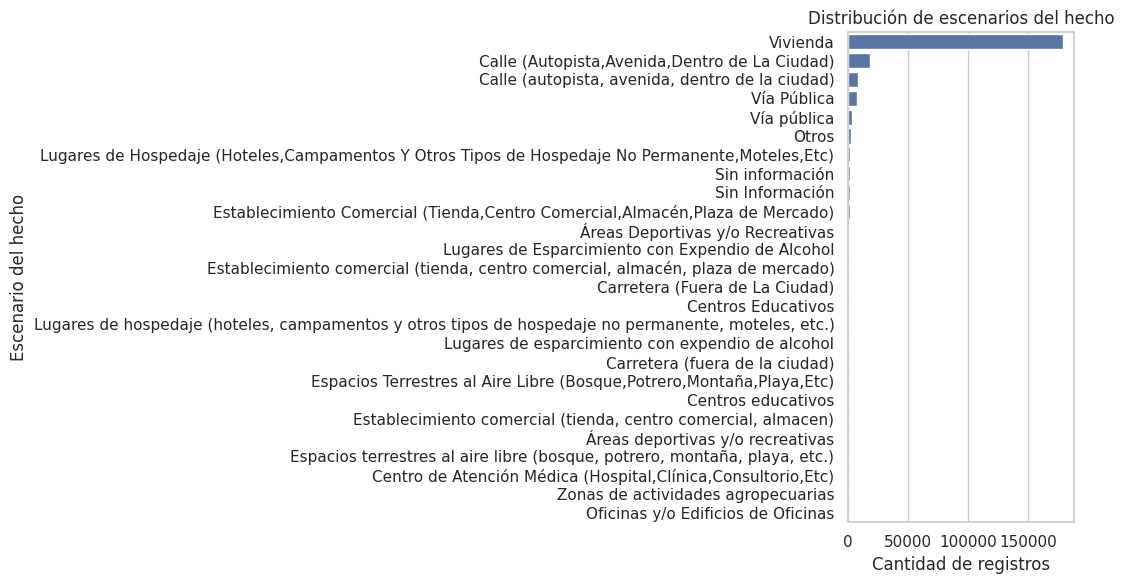

In [3]:
# ==========================================
# 1.2 DISTRIBUCIÓN DE LA VARIABLE OBJETIVO
# ==========================================

frecuencia_objetivo = (
    df_model[target]
    .value_counts()
    .sort_values(ascending=False)
)

porcentaje_objetivo = (
    df_model[target]
    .value_counts(normalize=True) * 100
)

resumen_objetivo = pd.DataFrame({
    "Frecuencia": frecuencia_objetivo,
    "Porcentaje": porcentaje_objetivo.round(2)
})

display(resumen_objetivo)

# Visualización
plt.figure(figsize=(11, 6))

sns.barplot(
    x=frecuencia_objetivo.values,
    y=frecuencia_objetivo.index
)

plt.title("Distribución de escenarios del hecho")
plt.xlabel("Cantidad de registros")
plt.ylabel("Escenario del hecho")

plt.tight_layout()
plt.show()

**Distribución de la Variable Objetivo**

Se examina la frecuencia de las categorías que componen la variable `escenario_del_hecho`.

- `value_counts()`: calcula la cantidad de registros por categoría.
- `value_counts(normalize=True)`: calcula la proporción de cada categoría.
- `sns.barplot()`: permite visualizar la distribución de las clases.

Esta revisión es importante porque permite identificar si existen diferencias importantes en la cantidad de registros por categoría.

Cuando una clase concentra una proporción considerablemente mayor que las demás, puede presentarse un problema de desbalance de clases.

Por esta razón, durante la evaluación se utilizarán métricas adicionales a la exactitud, especialmente F1-Score macro y Balanced Accuracy.

In [4]:
# ==========================================
# 1.3 PREPROCESAMIENTO Y SPLIT DE DATOS
# ==========================================

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Separar características y variable objetivo
X = df_model[features].copy()
y = df_model[target].copy()

# Identificar variables numéricas y categóricas
variables_numericas = [
    columna for columna in X.columns
    if pd.api.types.is_numeric_dtype(X[columna])
]

variables_categoricas = [
    columna for columna in X.columns
    if columna not in variables_numericas
]

# Convertir categorías a texto
for columna in variables_categoricas:
    X[columna] = X[columna].astype("object")

# Pipeline numérico
pipeline_numerico = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Pipeline categórico
pipeline_categorico = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Transformación completa
preprocessor = ColumnTransformer([
    ("num", pipeline_numerico, variables_numericas),
    ("cat", pipeline_categorico, variables_categoricas)
])

# Limitar el tamaño para facilitar el entrenamiento
# sin alterar intencionalmente la proporción de clases
if len(X) > 120000:

    X, _, y, _ = train_test_split(
        X,
        y,
        train_size=120000,
        stratify=y,
        random_state=42
    )

# División 80/20
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Preprocesamiento configurado.")
print("Variables numéricas:", variables_numericas)
print("Variables categóricas:", variables_categoricas)

print("\nEntrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)

Preprocesamiento configurado.
Variables numéricas: ['a_o_del_hecho']
Variables categóricas: ['sexo_de_la_victima', 'grupo_de_edad_quinquenal', 'ciclo_vital', 'escolaridad', 'estado_civil', 'departamento_del_hecho_dane', 'municipio_del_hecho_dane', 'mes_del_hecho', 'dia_del_hecho', 'presunto_agresor_detallado', 'contexto_del_hecho', 'factor_desencadenante_de_la_agresion', 'mecanismo_causal_de_la_lesion_no_fatal']

Entrenamiento: (96000, 14)
Prueba: (24000, 14)


**Preprocesamiento y División de Datos**

Antes de entrenar los modelos es necesario transformar la información para que los algoritmos puedan procesarla correctamente.

Se utilizan los siguientes procedimientos:

- **OneHotEncoder:** convierte las variables categóricas en representaciones numéricas mediante codificación binaria.
- **SimpleImputer:** reemplaza los valores faltantes de las variables numéricas mediante la mediana y los categóricos mediante la categoría más frecuente.
- **StandardScaler:** estandariza las variables numéricas para facilitar el entrenamiento de los modelos.

Se utiliza `ColumnTransformer` para aplicar cada procedimiento según el tipo de variable.

Posteriormente, se divide el conjunto de datos:

- 80% para entrenamiento.
- 20% para prueba.

Se utiliza `stratify=y` para conservar, en lo posible, la proporción de las categorías de la variable objetivo en ambos conjuntos.

Se establece una semilla `random_state=42` para facilitar la reproducibilidad de los resultados.

El preprocesamiento se integra en los pipelines de los modelos para evitar que la información del conjunto de prueba intervenga en el ajuste de las transformaciones.

In [5]:
# ==========================================
# 1.4 ENTRENAMIENTO Y EVALUACIÓN DE MODELOS
# ==========================================

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Modelos de clasificación
modelos = {
    "Modelo Base": DummyClassifier(strategy="most_frequent"),

    "Regresión Logística": LogisticRegression(
        max_iter=1500,
        class_weight="balanced"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=150,
        max_depth=20,
        min_samples_leaf=5,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    )
}

resultados = []
predicciones = {}

for nombre, modelo in modelos.items():

    # Construir pipeline completo
    pipeline_modelo = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", modelo)
    ])

    # Entrenamiento
    pipeline_modelo.fit(X_train, y_train)

    # Predicciones
    y_pred = pipeline_modelo.predict(X_test)

    predicciones[nombre] = y_pred

    # Evaluación
    resultados.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(
            y_test, y_pred
        ),
        "Precision Macro": precision_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ),
        "Recall Macro": recall_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ),
        "F1-Score Macro": f1_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        )
    })

    # Guardar el pipeline entrenado
    modelos[nombre] = pipeline_modelo

# Tabla comparativa
df_resultados = pd.DataFrame(resultados)

df_resultados = df_resultados.sort_values(
    "F1-Score Macro",
    ascending=False
).reset_index(drop=True)

print("--- COMPARATIVA DE MODELOS PREDICTIVOS ---")

display(
    df_resultados.round(4)
)

--- COMPARATIVA DE MODELOS PREDICTIVOS ---


,Modelo,Accuracy,Balanced Accuracy,Precision Macro,Recall Macro,F1-Score Macro
0,Regresión Logística,0.1435,0.3446,0.1028,0.3446,0.1042
1,Random Forest,0.1122,0.3428,0.1000,0.3428,0.0871
2,Modelo Base,0.7567,0.0385,0.0291,0.0385,0.0331


**Entrenamiento y Evaluación de Modelos Predictivos**

Se implementan tres alternativas para abordar el problema de clasificación.

### 1. Modelo Base (Dummy Classifier)

Es un modelo de referencia que predice la categoría más frecuente. Permite establecer un punto de comparación para determinar si los algoritmos de Machine Learning realmente aportan capacidad predictiva.

### 2. Regresión Logística

Es un algoritmo de clasificación que estima la probabilidad de pertenencia a cada categoría mediante una combinación de variables predictoras.

Se utiliza como modelo de referencia debido a su capacidad para abordar problemas de clasificación multiclase.

### 3. Random Forest Classifier

Es un algoritmo de ensamble que combina múltiples árboles de decisión para generar una clasificación.

Permite identificar relaciones no lineales y analizar la importancia relativa de las características utilizadas.

### Métricas de evaluación

- **Accuracy:** proporción de predicciones correctas sobre el total.
- **Balanced Accuracy:** promedio del rendimiento por clase, considerando el desbalance.
- **Precision Macro:** precisión promedio entre todas las categorías.
- **Recall Macro:** capacidad promedio para identificar correctamente los registros de cada categoría.
- **F1-Score Macro:** promedio de la combinación entre precisión y recall para todas las clases.

Se utiliza el promedio macro para evitar que las categorías con mayor cantidad de registros dominen completamente la evaluación.

El modelo base permite verificar si los modelos entrenados superan una estrategia de clasificación sin aprendizaje real.

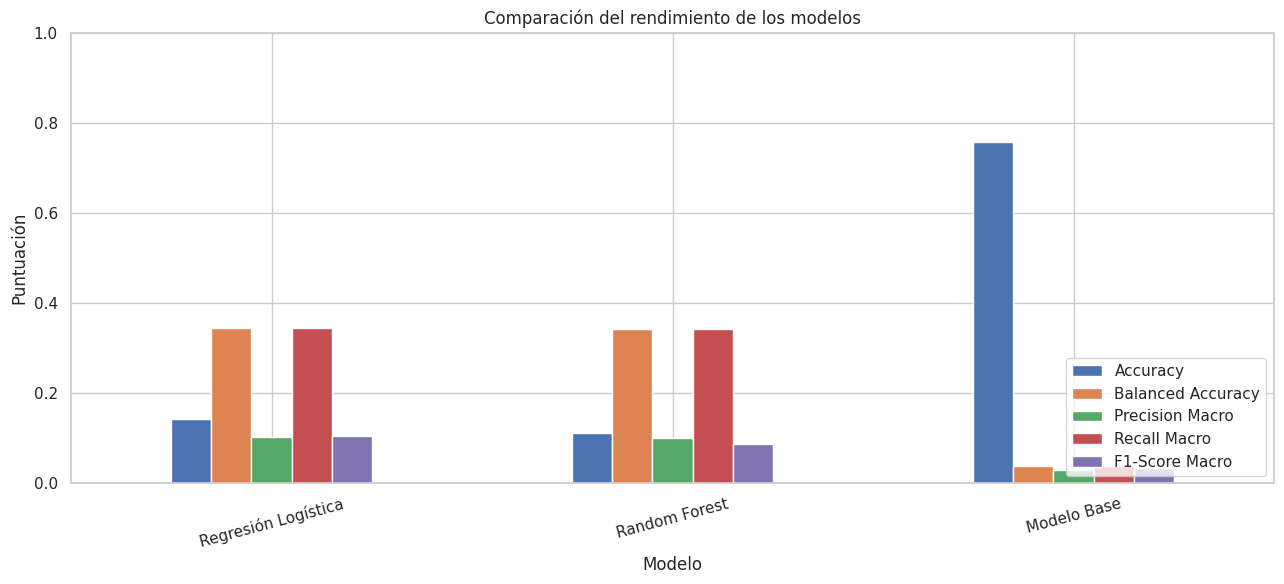

In [6]:
# ==========================================
# 1.5 COMPARACIÓN GRÁFICA DE LOS MODELOS
# ==========================================

metricas = [
    "Accuracy",
    "Balanced Accuracy",
    "Precision Macro",
    "Recall Macro",
    "F1-Score Macro"
]

df_grafico = df_resultados.set_index("Modelo")[metricas]

df_grafico.plot(
    kind="bar",
    figsize=(13, 6),
    ylim=(0, 1)
)

plt.title("Comparación del rendimiento de los modelos")
plt.ylabel("Puntuación")
plt.xlabel("Modelo")
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

Mejor modelo según F1-Score Macro: Regresión Logística

--- REPORTE DE CLASIFICACIÓN ---
                                                                                                     precision    recall  f1-score   support

                                                      Calle (Autopista,Avenida,Dentro de La Ciudad)       0.21      0.10      0.13      1862
                                                    Calle (autopista, avenida, dentro de la ciudad)       0.14      0.16      0.15       834
                                                                     Carretera (Fuera de La Ciudad)       0.04      0.33      0.07        85
                                                                     Carretera (fuera de la ciudad)       0.03      0.24      0.05        49
                                       Centro de Atención Médica (Hospital,Clínica,Consultorio,Etc)       0.01      0.24      0.01        29
                                                                

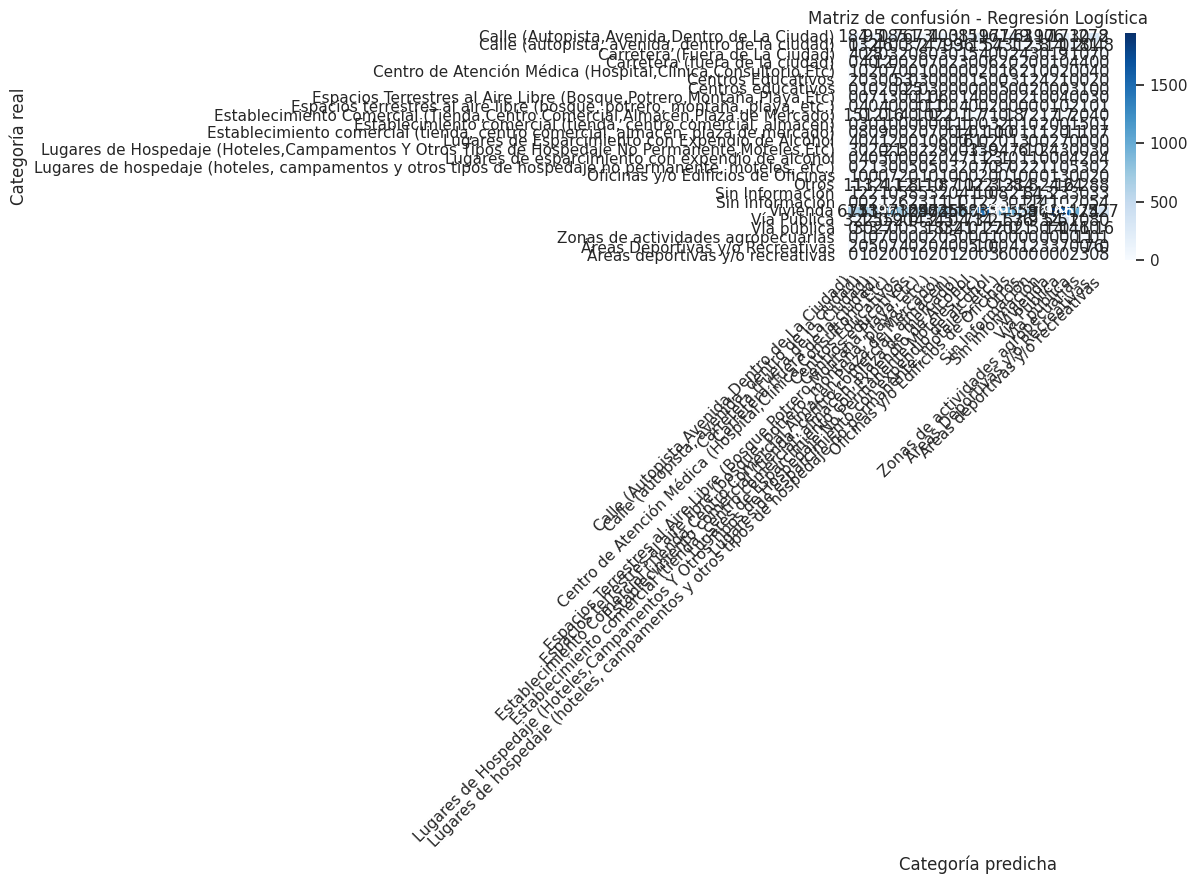

In [7]:
# ==========================================
# 1.6 MATRIZ DE CONFUSIÓN
# ==========================================

from sklearn.metrics import confusion_matrix

# Seleccionar el modelo con mayor F1 Macro
mejor_nombre = df_resultados.iloc[0]["Modelo"]

mejor_modelo = modelos[mejor_nombre]

y_pred_mejor = predicciones[mejor_nombre]

print("Mejor modelo según F1-Score Macro:", mejor_nombre)

# Reporte detallado
print("\n--- REPORTE DE CLASIFICACIÓN ---")

print(
    classification_report(
        y_test,
        y_pred_mejor,
        zero_division=0
    )
)

# Matriz de confusión
clases = mejor_modelo.named_steps[
    "classifier"
].classes_

matriz = confusion_matrix(
    y_test,
    y_pred_mejor,
    labels=clases
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=clases,
    yticklabels=clases
)

plt.title(f"Matriz de confusión - {mejor_nombre}")
plt.xlabel("Categoría predicha")
plt.ylabel("Categoría real")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

**Evaluación Detallada mediante la Matriz de Confusión**

La matriz de confusión permite comparar las categorías reales con las categorías estimadas por el modelo.

Su interpretación se realiza de la siguiente manera:

- Las filas representan las categorías reales.
- Las columnas representan las categorías predichas.
- La diagonal principal representa las clasificaciones correctas.
- Los valores fuera de la diagonal representan errores de clasificación.

El reporte de clasificación complementa esta visualización mediante Precision, Recall y F1-Score para cada categoría.

Se selecciona el modelo con el mayor F1-Score Macro para realizar esta evaluación detallada.

**Interpretación:** el modelo con mejores resultados no necesariamente será el que presente mayor Accuracy. Es importante comprobar que tenga un rendimiento razonable en las diferentes categorías y que supere al modelo base.

Las predicciones representan estimaciones de una categoría del registro, no predicciones de ocurrencia de violencia ni evaluaciones de riesgo de personas.

,Característica,Importancia
0,num__a_o_del_hecho,0.104205
1089,cat__presunto_agresor_detallado_Sin información,0.030212
1112,cat__factor_desencadenante_de_la_agresion_Sin ...,0.023591
1109,cat__factor_desencadenante_de_la_agresion_Into...,0.021334
1069,cat__presunto_agresor_detallado_Encargado del ...,0.020581
62,"cat__departamento_del_hecho_dane_Bogotá, D.C.",0.020251
1105,cat__factor_desencadenante_de_la_agresion_Cons...,0.018909
46,cat__escolaridad_Sin información,0.017664
1099,cat__contexto_del_hecho_3 Lesiones no Fatales ...,0.017575
1103,cat__factor_desencadenante_de_la_agresion_Alco...,0.017047


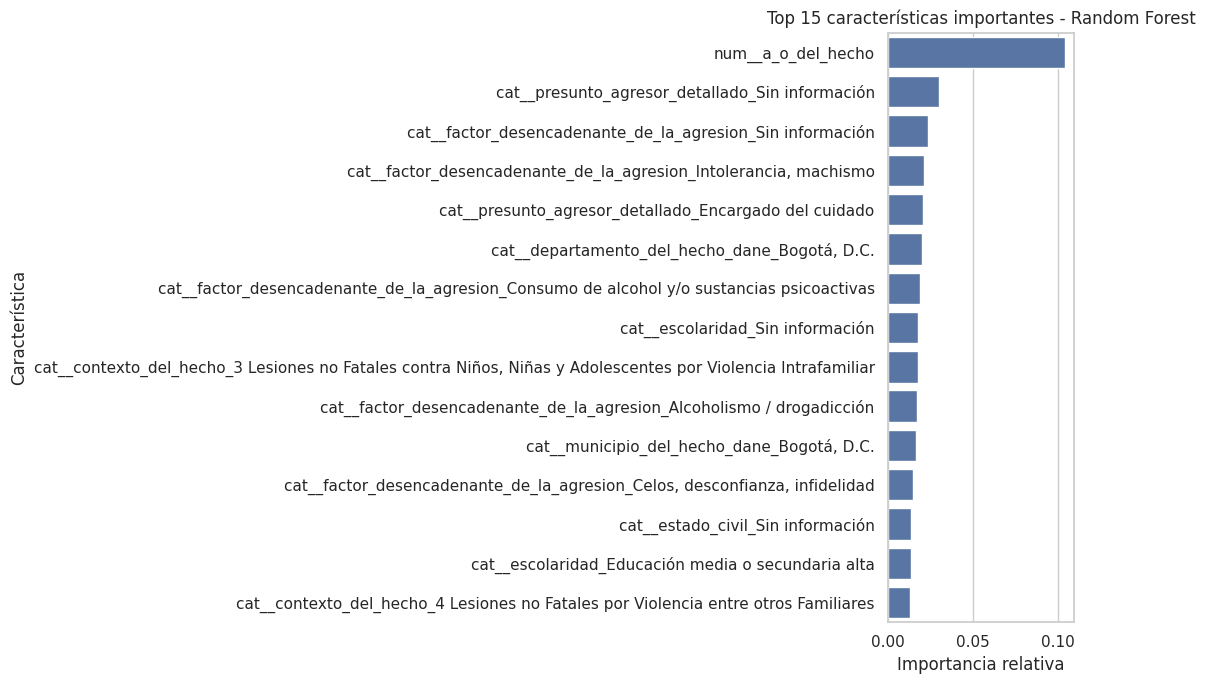

In [8]:
# ==========================================
# 1.7 IMPORTANCIA DE LAS VARIABLES
# ==========================================

# Utilizar Random Forest para obtener importancias
rf_pipeline = modelos["Random Forest"]

rf_model = rf_pipeline.named_steps["classifier"]

# Recuperar nombres de variables transformadas
nombres_variables = (
    rf_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

importancias = rf_model.feature_importances_

df_importancia = pd.DataFrame({
    "Característica": nombres_variables,
    "Importancia": importancias
})

df_importancia = df_importancia.sort_values(
    "Importancia",
    ascending=False
).head(15)

display(df_importancia)

# Visualización
plt.figure(figsize=(11, 7))

sns.barplot(
    data=df_importancia,
    x="Importancia",
    y="Característica"
)

plt.title("Top 15 características importantes - Random Forest")
plt.xlabel("Importancia relativa")
plt.ylabel("Característica")

plt.tight_layout()
plt.show()

**Importancia de las Variables en Random Forest**

En esta sección se identifican las características que más contribuyen a las decisiones de clasificación del modelo Random Forest.

El atributo `feature_importances_` permite obtener una medida de la importancia relativa de cada característica transformada.

Se seleccionan las quince características con mayor importancia y se representan mediante un gráfico de barras.

Esta información permite reconocer qué variables utiliza con mayor frecuencia el modelo para diferenciar las categorías del escenario del hecho.

**Consideraciones:**

- La importancia no representa causalidad.
- Una variable importante no significa que sea responsable de la ocurrencia de un hecho.
- Las variables correlacionadas pueden repartirse la importancia.
- Las características categóricas transformadas mediante One-Hot Encoding aparecen representadas individualmente.

Los resultados deben interpretarse como una explicación del comportamiento interno del modelo y no como una identificación de factores causales de violencia intrafamiliar.

---
## 2. Conclusiones de la Analítica Predictiva

En esta fase se desarrollaron modelos de clasificación para estimar el escenario del hecho registrado a partir de las características sociodemográficas, temporales, geográficas y contextuales disponibles.

Se compararon tres alternativas:

1. Modelo Base (Dummy Classifier).
2. Regresión Logística.
3. Random Forest Classifier.

La comparación se realizó mediante Accuracy, Balanced Accuracy, Precision Macro, Recall Macro y F1-Score Macro.

### Aspectos que deben analizarse

- ¿Cuál modelo obtuvo el mejor F1-Score Macro?
- ¿Qué diferencia existe entre el modelo base y los modelos entrenados?
- ¿Qué categorías presentan mayor dificultad de clasificación?
- ¿Qué variables tienen mayor importancia dentro del Random Forest?
- ¿El rendimiento obtenido es suficiente para considerar útil el modelo?

### Limitaciones

El modelo aprende patrones presentes en los registros históricos y su capacidad predictiva depende de la calidad y representatividad de los datos.

No permite establecer causalidad, identificar personas que sufrirán violencia ni anticipar individualmente la ocurrencia de hechos futuros.

Los resultados se utilizarán como insumo para la siguiente fase de analítica prescriptiva.

In [9]:
# ==========================================
# 2. EXPORTACIÓN DE RESULTADOS PREDICTIVOS
# ==========================================

from pathlib import Path
import shutil

carpeta_salida = Path("resultados_predictivos_violencia")
carpeta_salida.mkdir(exist_ok=True)

# Exportar comparación de modelos
df_resultados.to_csv(
    carpeta_salida / "comparacion_modelos.csv",
    index=False,
    encoding="utf-8-sig"
)

# Exportar importancia de variables
df_importancia.to_csv(
    carpeta_salida / "importancia_variables.csv",
    index=False,
    encoding="utf-8-sig"
)

# Exportar predicciones del mejor modelo
df_predicciones = pd.DataFrame({
    "Categoria_real": y_test.values,
    "Categoria_predicha": y_pred_mejor
})

df_predicciones.to_csv(
    carpeta_salida / "predicciones_modelo.csv",
    index=False,
    encoding="utf-8-sig"
)

# Crear archivo comprimido
archivo_zip = shutil.make_archive(
    "resultados_predictivos_violencia",
    "zip",
    carpeta_salida
)

print("Resultados exportados correctamente.")
print("Archivo:", archivo_zip)

Resultados exportados correctamente.
Archivo: /content/resultados_predictivos_violencia.zip
